# Decision Tree
This notebook trains a Decision Tree to predict gallstone disease, using features from the data exploration.

### Type of machine learning:
Binary classification: 0 = gallstones, 1 = no gallstones.

### Model justification:
A Decision Tree learns simple rules from feature values. It is easy to visualize, but can overfit.


### Research question:
How well does the tree predict gallstones, and does tuning improve it?

### Splitting criteria:
The initial tree uses Gini impurity:

$$
G = 1 - (p_0^2 + p_1^2)
$$

A lower value means less mixed classes. Tuning also tests entropy.

## Training:

Data is loaded through data_loader.py, then cleaned using cells from the data part notebook. 
We keep its seven features and 80/20 stratified split (seed 37). The tree uses seed 77.
The selected features have no missing values. A tree does not need scaling.

### Initial install of libraries/packages
Uncomment if needed.

In [48]:
#%pip install -q pandas numpy scikit-learn matplotlib nbformat # installerer pakkene i notebookens Python-miljø

### Import library

In [ ]:
from __future__ import annotations # lar typebeskrivelsene brukes uten å påvirke kjøringen.
from typing import Any # beskriver data som hentes dynamisk.
import json # leser kildekoden i datanotebooken uten ekstra notebook-pakker
from pathlib import Path # lager relative filstier i repoet
import pandas as pd # leser CSV-filen og jobber med tabeller
import numpy as np # lager tallrekker til grafene
import matplotlib.pyplot as plt # tegner grafer
from IPython.utils.capture import capture_output # skjuler ekstra utskrift fra datanotebooken
from sklearn import tree, model_selection as ms, metrics, compose, pipeline # henter modell- og evalueringsverktøy
from sklearn.base import clone # kopierer modell og scaler uten å ta med tidligere tilpasning
from sklearn.preprocessing import StandardScaler # beskriver skaleringen fra datanotebooken
from matplotlib.container import BarContainer # gjenkjenner stolpene som kan få verdietiketter
from numpy.typing import NDArray # beskriver tallrekkene med modellens svar og sannsynligheter

### Plot settings and class labels

In [ ]:
# Setter opp figuren og skriftstørrelsen
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11}) # velger figur- og skriftstørrelse
COLORS = ["#2878A7", "#6C7A35", "#CB762D"] # velger fargene til grafene
CLASS_NAMES = ["Gallstones (0)", "No gallstones (1)"] # gir navn til klasse 0 og 1

### Preprocessing from data notebook

In [ ]:
# Laster inn datalasteren fra src-mappen
from src.data_loader import load_data

DATA_PATH = Path("dataset-uci.csv")
DATA_NOTEBOOK = Path("Data_part1_final.ipynb")
source = json.loads(DATA_NOTEBOOK.read_text(encoding="utf-8"))

source_data: dict[str, Any] = {
    "pd": pd, 
    "np": np, 
    "display": display,
    "galle_set": load_data(DATA_PATH, "Gallstone Status")
    }

cell_numbers = [33, 35, 36, 52, 53, 56, 58, 61, 63, 67, 69, 71] 
with capture_output():
    for i in cell_numbers: 
        exec("".join(source["cells"][i]["source"]), source_data)

### Variables from data notebook

In [ ]:
# Henter de forberedte dataene fra datanotebooken
galle_set = source_data["galle_set"] # renset datasett
continous_features = source_data["continous_features"] #  numeriske variabler som undersøkes og skaleres
outlier_results = source_data["outlier_results"] # listen med resultater fra IQR-analysen
outlier_summary = source_data["outlier_summary"] # tabellen som oppsummerer uteliggere per variabel
suspicious_rows = source_data["suspicious_rows"] # mistenkelige rader fra undersøkelsen før erstatning
X = source_data["X"] # alle forklaringsvariablene, uten "Gallstone Status"
y = source_data["y"] # målvariabelen "Gallstone Status"
X_train = source_data["X_train"] # alle forklaringsvariablene for de 80 prosentene som brukes til trening
X_test = source_data["X_test"] # alle forklaringsvariablene for de 20 prosentene som brukes til test
y_train = source_data["y_train"] # fasit for treningspasientene
y_test = source_data["y_test"] # fasit for testpasientene
scaler = source_data["scaler"] # standardScaler tilpasset kontinuerlige variabler i hele treningssettet
correlation = source_data["correlation"] # korrelasjonen mellom  numeriske forklaringsvariabel og målvariabel
top_features = source_data["top_features"] # de ti variablene med høyest absolutt korrelasjon med målvariabelen
selected_features = list(source_data["selected_features"]) # en lokal kopi av de sju variablene valgt til modellering
feature_correlation = source_data["feature_correlation"] # korrelasjonsmatrisen mellom de ti variablene i top_features

# Viser informasjon om det forberedde datasettet
print("Prepared data:", 
      galle_set.shape, 
      "Suspicious rows:", 
      len(suspicious_rows)
      )

# Viser de 14 første variablene med flest uteliggere, og antall uteliggere for hver
outlier_summary[["Feature", "Number of outliers"]].head(14)

Prepared data: (319, 39) Suspicious rows: 8


,Feature,Number of outliers
28,C-Reactive Protein (CRP),34
24,Alanin Aminotransferaz (ALT),27
18,Glucose,25
23,Aspartat Aminotransferaz (AST),23
22,Triglyceride,20
25,Alkaline Phosphatase (ALP),12
27,Glomerular Filtration Rate (GFR),10
10,Body Protein Content (Protein) (%),8
15,Total Fat Content (TFC),7
7,Extracellular Fluid/Total Body Water (ECF/TBW),7


### Models input from existing split

In [ ]:
# Velger de kontinuerlige variablene som skal brukes i modelleringen
model_continous: list[str] = [name for name in selected_features if name in continous_features]

# Lager trenings- og testsett med de sju forklaringsvariablene som skal brukes i modelleringen
X_train_model: pd.DataFrame = galle_set.loc[X_train.index, selected_features]
X_test_model: pd.DataFrame = galle_set.loc[X_test.index, selected_features]

# Lager en StratifiedKFold med fem faste valideringsfold
cv = ms.StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=37
    )

# Viser størrelsen på trenings- og testsettene
print(
    "Training patients:", 
    len(X_train_model), 
    "Test patients:", 
    len(X_test_model)
    )

Training patients: 255 Test patients: 64


### Initial tree and max depth = 3
Compare average accuracy over five training folds. Test data is kept for evaluation.

In [ ]:
# Kobler skalering og klassifikasjon til én modell
scale_features = compose.ColumnTransformer( 
    [("continuous", clone(scaler), model_continous)], 
    remainder="passthrough", 
    verbose_feature_names_out=False
) 

# Lager starttreet med fast seed
decision_tree = pipeline.Pipeline([
    ("scale", scale_features),
    ("tree", tree.DecisionTreeClassifier(random_state=77))
])

# Lager en kopi av starttreet med treets maksdybde satt til 3
small_tree: pipeline.Pipeline = clone(decision_tree).set_params(tree__max_depth=3)

# Tester begge trærne med femfolds kryssvalidering og viser gjennomsnittlig nøyaktighet
for name, model in [("Initial tree", decision_tree), ("Depth 3 tree", small_tree)]: 
    scores = ms.cross_val_score(
        model, 
        X_train_model, 
        y_train, 
        cv=cv, 
        scoring="accuracy"
        )
    print(f"{name}: CV accuracy = {scores.mean():.3f}")

Initial tree: CV accuracy = 0.722
Depth 3 tree: CV accuracy = 0.678


### Optimizing tree
GridSearchCV tests 432 combinations on training data and keeps the best average accuracy. It tests splitting rules, tree size and pruning.

In [ ]:
# Setter opp kombinasjoner av innstillingene i param_grid
param_grid = { 
    "tree__criterion": ["gini", "entropy"], # prøver to måter å velge delinger på
    "tree__max_depth": [2, 3, 4, 5, 6, None], # prøver ulike dybder
    "tree__min_samples_split": [2, 10, 20], # minste antall pasienter for å dele en node
    "tree__min_samples_leaf": [1, 3, 5, 10], # minste antall pasienter i en sluttnode
    "tree__ccp_alpha": [0.0, 0.005, 0.02] # prøver ulike grader av beskjæring
}

# Lager grid search-objektet med femfolds kryssvalidering og nøyaktighet som evalueringsmetode
grid_search = ms.GridSearchCV(
    decision_tree, 
    param_grid, 
    cv=cv,
    scoring="accuracy", 
    error_score="raise"
    )

# Trener grid search-objektet på treningsdataene og henter ut den beste modellen
grid_search.fit(X_train, y_train)
best_tree = grid_search.best_estimator_

# Viser de beste innstillingene og gjennomsnittlig nøyaktighet for den beste modellen
print("Best parameters:", grid_search.best_params_)
print(f"Best CV accuracy: {grid_search.best_score_:.3f}")

Best parameters: {'tree__ccp_alpha': 0.0, 'tree__criterion': 'entropy', 'tree__max_depth': 5, 'tree__min_samples_leaf': 10, 'tree__min_samples_split': 2}
Best CV accuracy: 0.702


### Calculate training and testing results
All three trees use the same test set. 
- Recall measures how many gallstone cases are found
- ROC-AUC measures how well the model separates the groups.

In [ ]:
# Viser de tre modellene som skal evalueres
models = {
    "Initial tree": decision_tree, 
    "Depth 3 tree": small_tree, 
    "Tuned tree": best_tree
}

# Lagrer modellens svar og sannsynligheter for testpasientene, og lager en tabell med resultater
predictions = {} # lagring av modellens svar for testpasientene
probabilities = {} # lagring av  sannsynligheten for gallestein
rows = [] # lagring av en enkel resultatlinje per modell

# Går gjennom alle tre modellene, trener dem på treningssettet, predikerer klassen til testpasientene, henter sannsynligheten for gallestein, og legger resultatene i tabellen
for name, model in models.items(): # går gjennom alle tre modellene
    model.fit(X_train, y_train) # trener modellen på treningssettet
    predictions[name] = model.predict(X_test) # predikerer klassen til testpasientene
    probabilities[name] = model.predict_proba(X_test)[:, 0] # henter sannsynligheten for klasse 0: gallestein
    rows.append({ # legger modellens resultater i tabellen
        "Model": name, "Train accuracy": model.score(X_train, y_train), # lagrer navn og treningsnøyaktighet
        "Test accuracy": model.score(X_test, y_test), # lagrer nøyaktigheten på testsettet
        "Gallstone recall": metrics.recall_score(y_test, predictions[name], pos_label=0), # andel gallesteinstilfeller funnet
        "ROC-AUC": metrics.roc_auc_score(y_test == 0, probabilities[name]) # måler hvor godt gruppene skilles
    }
    )

    # Viser forvekslingsmatrisen for hver modell
results = pd.DataFrame(rows).set_index("Model")

print(metrics.classification_report(
    y_test, 
    predictions["Tuned tree"], 
    labels=[0, 1], 
    target_names=CLASS_NAMES, 
    digits=3
    )
)
results.round(3)

                   precision    recall  f1-score   support

   Gallstones (0)      0.688     0.688     0.688        32
No gallstones (1)      0.688     0.688     0.688        32

         accuracy                          0.688        64
        macro avg      0.688     0.688     0.688        64
     weighted avg      0.688     0.688     0.688        64



,Train accuracy,Test accuracy,Gallstone recall,ROC-AUC
Model,,,,
Initial tree,1.000,0.594,0.562,0.594
Depth 3 tree,0.784,0.609,0.438,0.778
Tuned tree,0.816,0.688,0.688,0.743


### Training and test accuracy

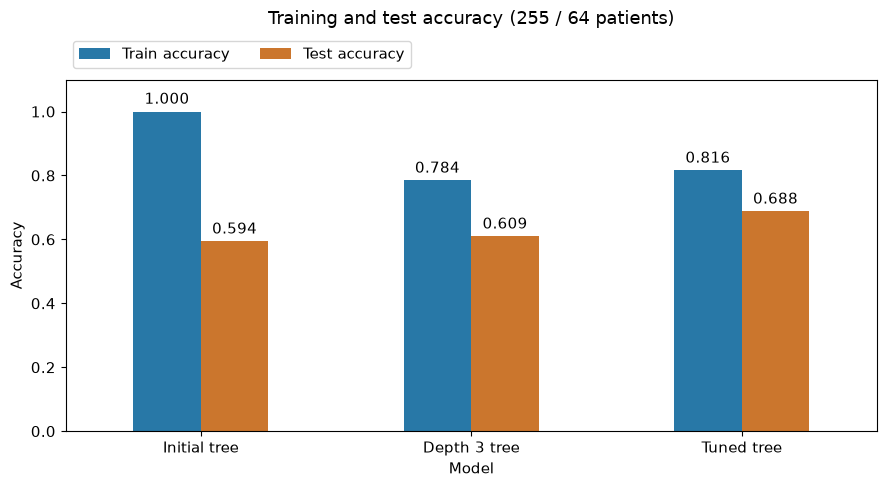

In [ ]:
# Lager stolpediagrammet med trenings- og testnøyaktighet for alle tre modellene
ax = results[["Train accuracy", "Test accuracy"]].plot.bar( 
    color=[COLORS[0], COLORS[2]], 
    rot=0, 
    ylim=(0, 1.1)
)

# Legger til navn på aksene, tittel og verdier over stolpene
ax.set(xlabel="Model", ylabel="Accuracy")
ax.set_title("Training and test accuracy (255 / 64 patients)", pad=40)
for bars in ax.containers:
    ax.bar_label(bars, 
                 fmt="%.3f", 
                 padding=3
                )
ax.legend(
    loc="lower left", 
    bbox_to_anchor=(0, 1.01), 
    ncols=2
    )

# Lager forvekslingsmatrisene for starttreet og det fininnstilte treet
plt.tight_layout()
plt.show()

### Confusion matrix

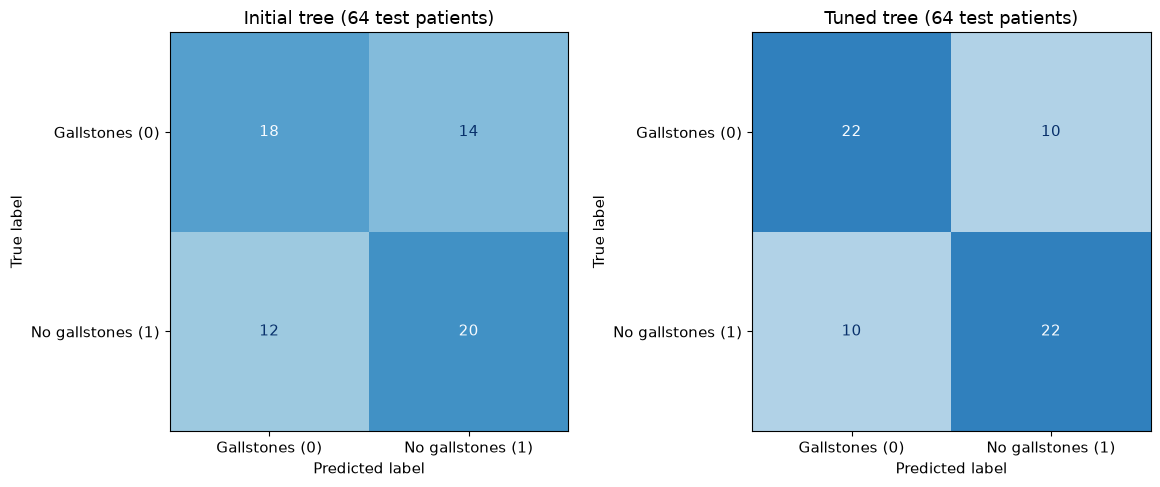

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # lager to grafer ved siden av hverandre
for ax, name in zip(axes, ["Initial tree", "Tuned tree"]): # velger ett tre til hver graf
    metrics.ConfusionMatrixDisplay.from_predictions( # sammenligner fasit med modellens svar
        y_test, predictions[name], labels=[0, 1], display_labels=CLASS_NAMES, # bruker samme klasserekkefølge
        ax=ax, cmap="Blues", colorbar=False, # tegner på riktig plass med blå farger
        im_kw={"vmin": 0, "vmax": y_test.value_counts().max()} # bruker lik fargeskala i begge grafer
    )
    ax.set_title(f"{name} (64 test patients)") # viser modellnavn og antall testpasienter
plt.tight_layout() # sørger for at navn og akser får plass
plt.show() # viser begge matrisene

### ROC graph

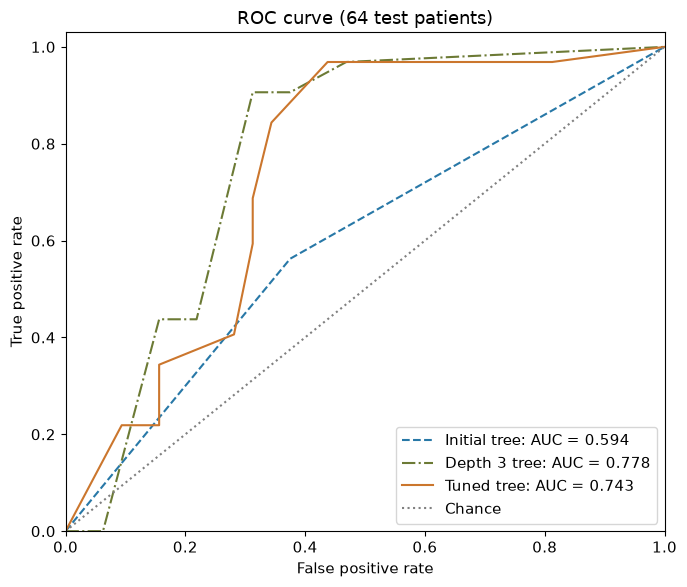

In [36]:
fig, ax = plt.subplots(figsize=(7, 6)) # lager en figur til ROC-kurvene
for name, color, style in zip(models, COLORS, ["--", "-.", "-"]): # gir hver modell egen farge og linjestil
    fpr, tpr, _ = metrics.roc_curve(y_test == 0, probabilities[name]) # beregner feildiagnoser og treff ved ulike grenser
    auc = results.loc[name, "ROC-AUC"] # henter AUC-resultatet fra tabellen
    ax.plot(fpr, tpr, color=color, linestyle=style, label=f"{name}: AUC = {auc:.3f}") # tegner modellens ROC-kurve
ax.plot([0, 1], [0, 1], ":", color="grey", label="Chance") # tegner referansen for tilfeldig rangering
ax.set(title="ROC curve (64 test patients)", xlabel="False positive rate", # setter tittel og x-akse
       ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.03)) # setter y-akse og aksenes grenser
ax.legend() # viser hvilken kurve som tilhører hver modell
plt.tight_layout() # tilpasser avstanden rundt figuren
plt.show() # viser ROC-kurvene

### Visualizing tuned tree

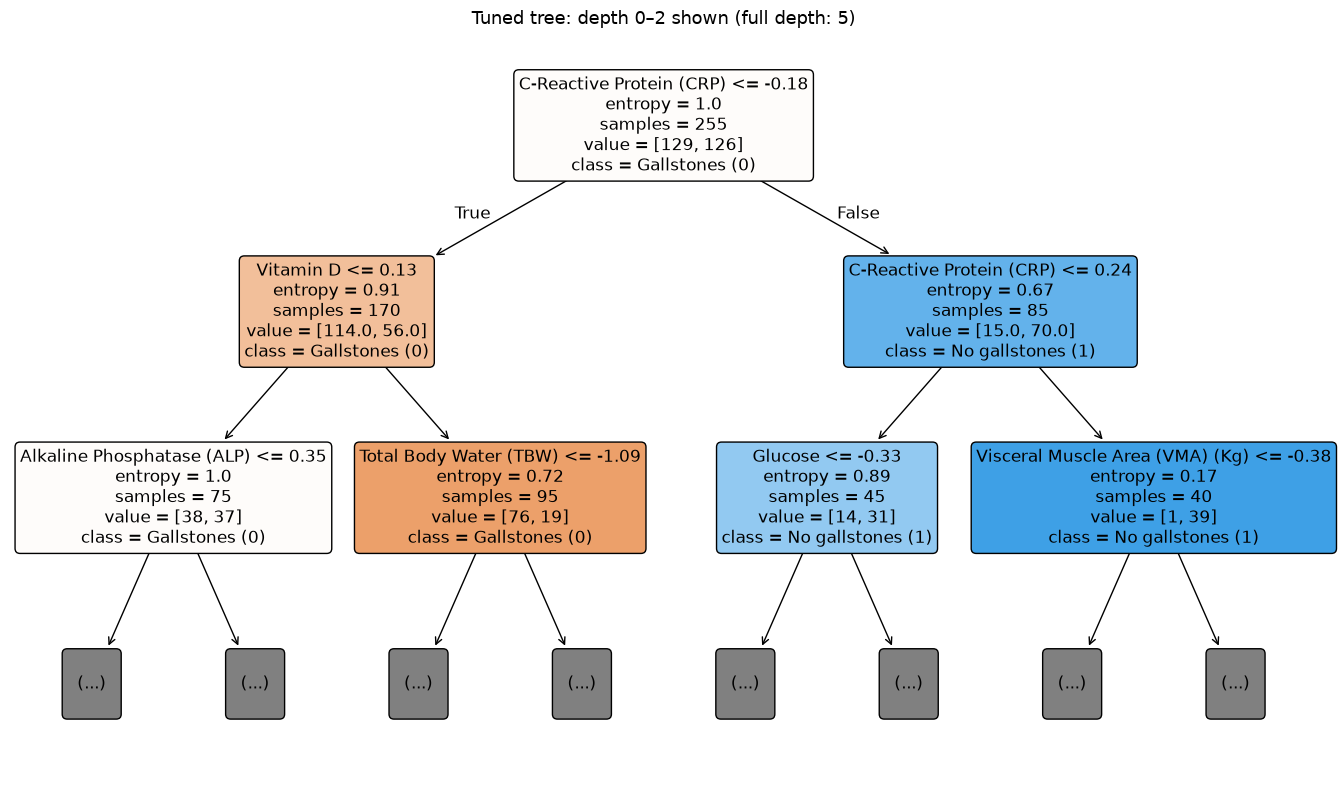

In [ ]:
fitted_tree = best_tree.named_steps["tree"]
plot_labels = best_tree.named_steps["scale"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(14, 8)) # lager en stor figur til treet
tree.plot_tree(fitted_tree,
               feature_names=plot_labels,
               class_names=CLASS_NAMES,
               filled=True,
               rounded=True,
               max_depth=2, 
               precision=2,
               fontsize=12,
               ax=ax
               )

ax.set_title(f"Tuned tree: depth 0–2 shown (full depth: {fitted_tree.get_depth()})") # oppgir treets virkelige dybde
plt.tight_layout() # gir boksene og tittelen plass
plt.show() # viser treet med lærte regler

### Tree depth and overfitting

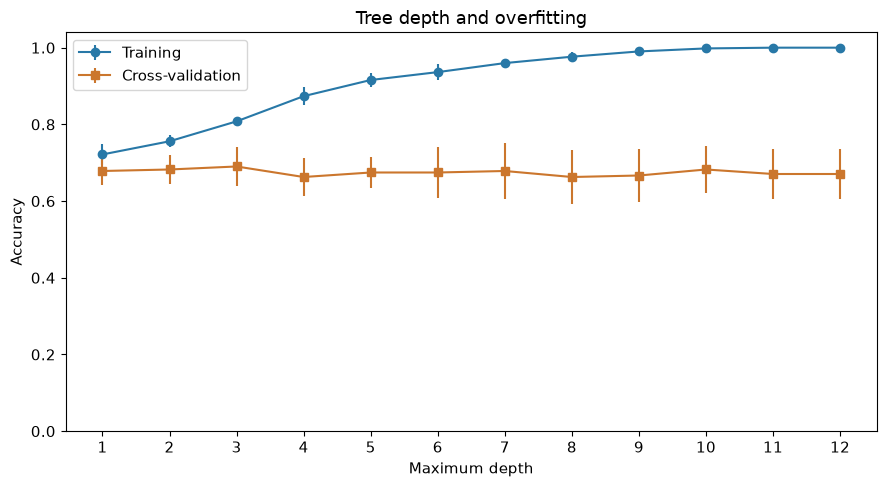

In [46]:
depths = np.arange(1, 13) # velger dybdene 1 til og med 12
depth_train, depth_cv = ms.validation_curve( # måler resultatene ved ulike maksimale dybder.
    decision_tree, 
    X_train, 
    y_train, 
    param_name="tree__max_depth",
    param_range=depths, 
    cv=cv, 
    scoring="accuracy"
)
fig, ax = plt.subplots() # lager figuren
ax.errorbar(
    depths, 
    depth_train.mean(axis=1), 
    yerr=depth_train.std(axis=1), # beregner snitt og spredning for trening
    color=COLORS[0], 
    fmt="o-", 
    label="Training"
    ) # tegner treningskurven med sirkler
ax.errorbar(
    depths, 
    depth_cv.mean(axis=1), 
    yerr=depth_cv.std(axis=1), # beregner snitt og spredning for validering
    color=COLORS[2], 
    fmt="s-", 
    label="Cross-validation"
    ) # tegner valideringskurven med firkanter
ax.set(
    title="Tree depth and overfitting", 
    xlabel="Maximum depth", 
    ylabel="Accuracy",
    ylim=(0, 1.04), 
    xticks=depths
   ) # setter tittel, aksebeskrivelser og aksenes grenser
ax.legend() # forklarer de to kurvene
plt.tight_layout() # sørger for at teksten får plass
plt.show() # viser hvordan dybden påvirker resultatene

### Prints results

In [12]:
testOut = pd.DataFrame({"Actual": y_test, "Predicted": predictions["Tuned tree"]}) # samler fasit og modellens svar
testOut.head(10) # viser de ti første testpasientene

,Actual,Predicted
310,1,1
130,0,0
245,1,1
144,0,1
26,0,0
239,1,1
175,1,1
126,0,1
99,0,0
247,1,1


## Conclusion (before cleansed data)
- tuning improves test accuracy from 67.2% to 75.0%
- the depth-3 tree scores 79.7% on this test set. Tuning follows training CV, not test ranking
- the tuned tree finds 22 of 32 gallstone cases, but still overfits (100% training accuracy)

### References

Decision Tree: https://scikit-learn.org/stable/modules/tree.html

Grid Search: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html